In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [64]:
from sklearn.datasets import load_diabetes

In [65]:
dataset = load_diabetes(as_frame=True)
df = dataset.frame.copy()
df


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [66]:
df.columns

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'target'],
      dtype='str')

In [67]:
df.rename(columns={'target': 'disease_progression'}, inplace=True)

In [68]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [69]:
df.shape

(442, 11)

In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  disease_progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [71]:
df.isnull().sum()

age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3                     0
s4                     0
s5                     0
s6                     0
disease_progression    0
dtype: int64

In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


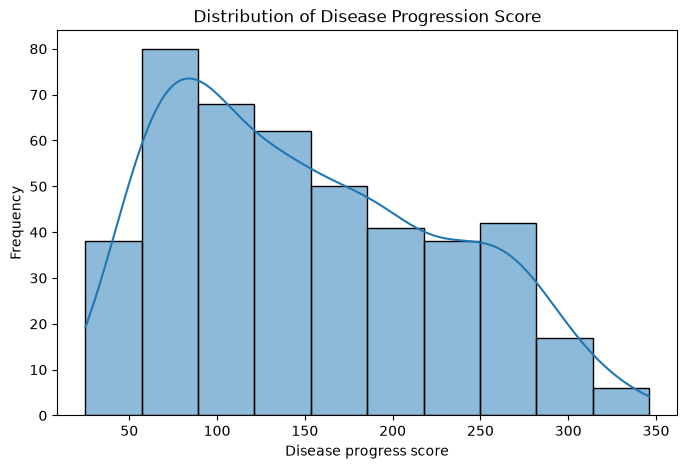

In [74]:
plt.figure(figsize=(8,5))
sns.histplot(df['disease_progression'], kde=True)
plt.title("Distribution of Disease Progression Score")
plt.xlabel("Disease progress score")
plt.ylabel("Frequency")
plt.show()

In [75]:
corr_matrix = df.corr()
corr_matrix

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


<Axes: >

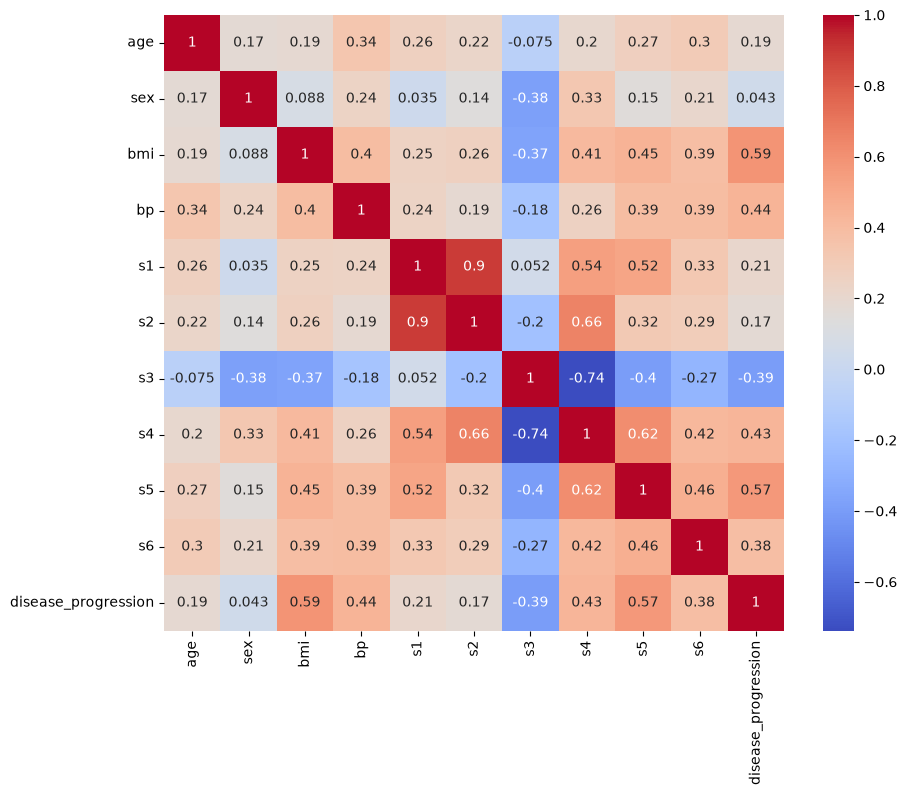

In [76]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')

In [77]:
def cap_outlier_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Pull values outside the bounds back to the nearest bound
    data[column] = data[column].clip(lower=lower_bound, upper=upper_bound)
    return data


In [78]:
outlier_columns = ['bmi', 's1', 's2', 's3', 's4', 's5', 's6']

for column in outlier_columns:
    df = cap_outlier_iqr(df, column)

df[outlier_columns].describe()

,bmi,s1,s2,s3,s4,s5,s6
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,-0.000181,-0.000212,-0.000353,-0.000533,-0.000114,-0.000021,-0.000130
std,0.047056,0.047019,0.046527,0.045934,0.047227,0.047561,0.046997
min,-0.090275,-0.126781,-0.115613,-0.102307,-0.076395,-0.126097,-0.124823
25%,-0.034229,-0.034248,-0.030358,-0.035117,-0.039493,-0.033246,-0.033179
50%,-0.007284,-0.004321,-0.003819,-0.006584,-0.002592,-0.001947,-0.001078
75%,0.031248,0.028358,0.029844,0.029312,0.034309,0.032432,0.027917
max,0.129464,0.122267,0.120149,0.125954,0.145012,0.130949,0.119561


In [79]:
from sklearn.model_selection import train_test_split

# X = the features (inputs), y = the target (value we want to predict)
X = df.drop(columns='disease_progression')
y = df['disease_progression']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (353, 10)
Test set: (89, 10)


In [80]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn the mean and std from the training set only, then apply to both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [81]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 1.77,-11.81, 25.07,..., 15.98, 37.68, 2.21]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,153.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[37.51,22.89,20.93,...,12.36, 4.94, 1.89]"


In [82]:
from sklearn.metrics import mean_absolute_error, r2_score

# Predict on data the model has never seen
y_pred = model.predict(X_test_scaled)

print(f"R2 score: {r2_score(y_test, y_pred):.3f}")
print(f"Mean absolute error: {mean_absolute_error(y_test, y_pred):.1f}")

R2 score: 0.452
Mean absolute error: 42.6


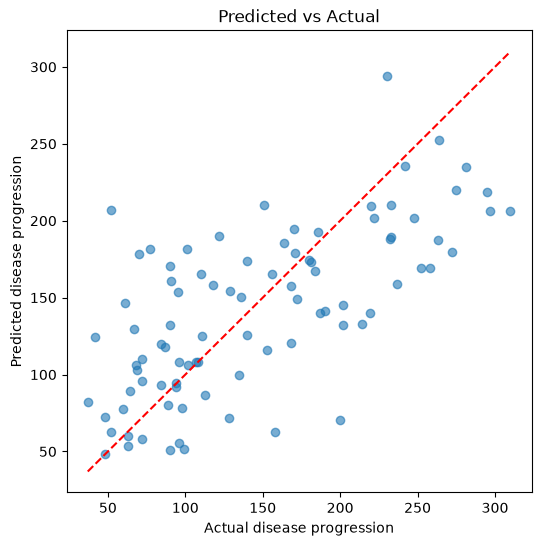

In [83]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

# Diagonal line = a perfect prediction
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.xlabel("Actual disease progression")
plt.ylabel("Predicted disease progression")
plt.title("Predicted vs Actual")
plt.show()

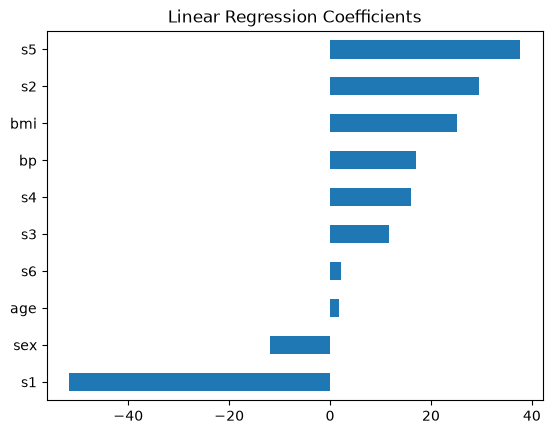

In [84]:
coefficients = pd.Series(model.coef_, index=X.columns)
coefficients.sort_values().plot(kind='barh')
plt.title("Linear Regression Coefficients")
plt.show()

In [85]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

# Train each model and score it on the same test set
results = []
for name, candidate in models.items():
    candidate.fit(X_train_scaled, y_train)
    predictions = candidate.predict(X_test_scaled)
    results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.sort_values("R2", ascending=False).round(3)

,R2,MAE
Model,,
Ridge Regression,0.453,42.660
Linear Regression,0.452,42.612
Random Forest,0.441,44.186


In [86]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

cv_results = []
for name, candidate in models.items():
    # A pipeline scales the data, then trains the model, as one unit
    pipeline = make_pipeline(StandardScaler(), candidate)
    scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='r2')
    cv_results.append({
        "Model": name,
        "Mean R2": scores.mean(),
        "Std": scores.std(),
    })

cv_df = pd.DataFrame(cv_results).set_index("Model")
cv_df.sort_values("Mean R2", ascending=False).round(3)

,Mean R2,Std
Model,,
Ridge Regression,0.454,0.142
Linear Regression,0.452,0.150
Random Forest,0.393,0.147


In [87]:
from sklearn.model_selection import GridSearchCV

ridge_pipeline = make_pipeline(StandardScaler(), Ridge())

# Values of alpha to try
param_grid = {'ridge__alpha': [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(ridge_pipeline, param_grid, cv=5, scoring='r2')
grid_search.fit(X_train, y_train)

print("Best alpha:", grid_search.best_params_)
print(f"Best cross-validation R2: {grid_search.best_score_:.3f}")

# Final check on the test set, using the best model
best_model = grid_search.best_estimator_
final_pred = best_model.predict(X_test)

print(f"Test R2: {r2_score(y_test, final_pred):.3f}")
print(f"Test MAE: {mean_absolute_error(y_test, final_pred):.1f}")

Best alpha: {'ridge__alpha': 10}
Best cross-validation R2: 0.456
Test R2: 0.456
Test MAE: 42.8
